<a href="https://colab.research.google.com/github/ahzan457/California-Housing-Price-Prediction/blob/main/California_Housing_Price_Prediction_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!

Dataset loaded! Shape: (20640, 9)

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

--- MISSING VALUES CHECK ---
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

--- STATISTICAL SUMMARY ---
         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccu

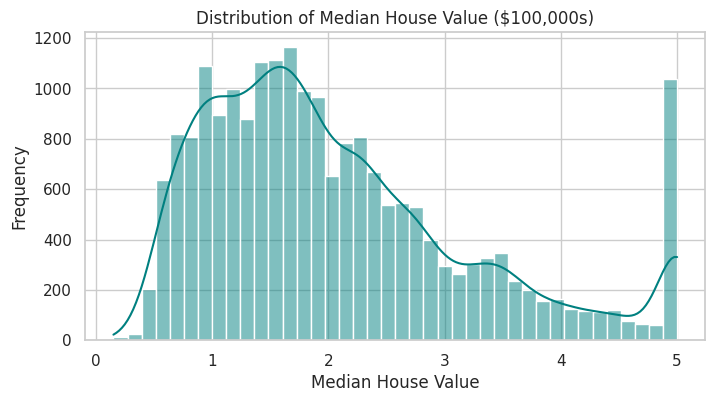

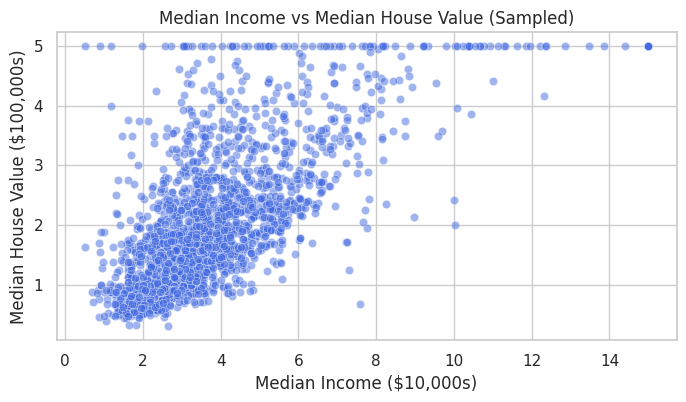

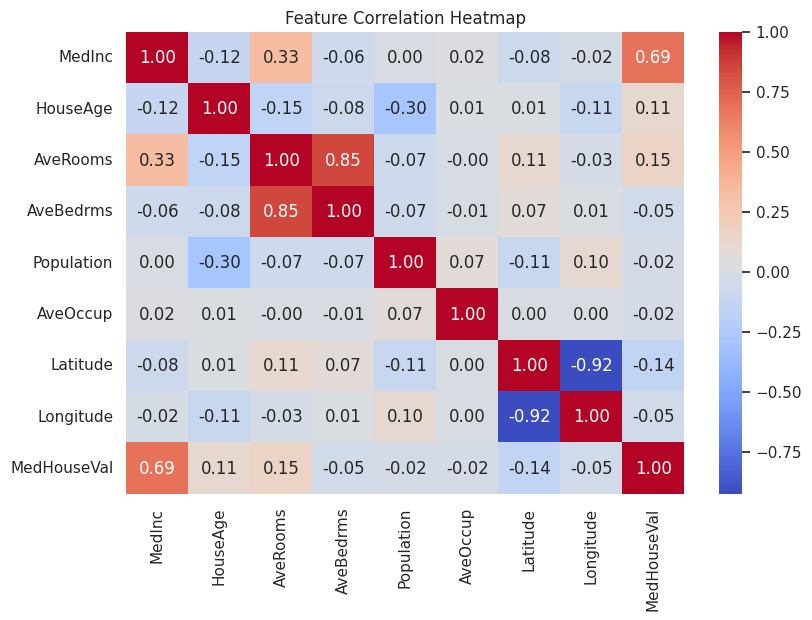


Train set: 16512 samples | Test set: 4128 samples

--- MODEL PERFORMANCE COMPARISON ---
Linear Regression -> R2 Score: 0.5758 | MAE: 0.5332
Random Forest     -> R2 Score: 0.8037 | MAE: 0.3303


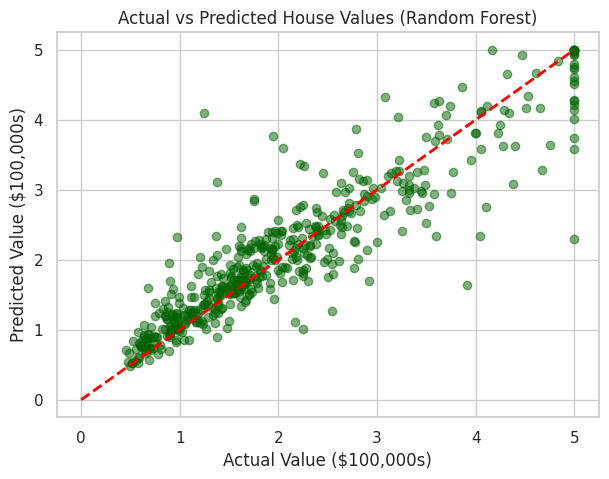

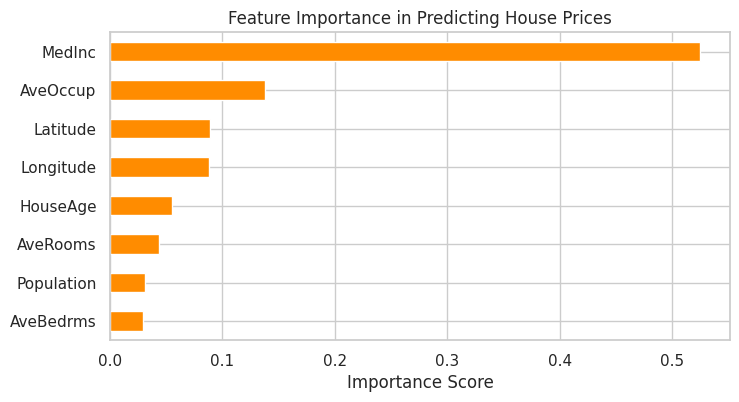


Capstone Project Execution Completed Successfully!


In [1]:
# ============================================================
# MODULE 06: FINAL DATA SCIENCE CAPSTONE PROJECT
# Project: California Housing Price Prediction (EDA + ML)
# ============================================================

# 1. IMPORT LIBRARIES
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%matplotlib inline
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

# 2. LOAD REAL-WORLD DATASET
housing = fetch_california_housing(as_frame=True)
df = housing.frame
print(f"\nDataset loaded! Shape: {df.shape}")
print("\nFirst 5 rows:")
print(df.head())

# 3. DATA QUALITY CHECK & SUMMARY
print("\n--- MISSING VALUES CHECK ---")
print(df.isnull().sum())

print("\n--- STATISTICAL SUMMARY ---")
print(df.describe().round(2))

# 4. EXPLORATORY DATA ANALYSIS (VISUALIZATIONS)

# Plot 1: Distribution of Target Variable (Median House Value)
plt.figure(figsize=(8, 4))
sns.histplot(df['MedHouseVal'], bins=40, kde=True, color='teal')
plt.title('Distribution of Median House Value ($100,000s)')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

# Plot 2: Median Income vs House Value Scatter Plot
plt.figure(figsize=(8, 4))
sns.scatterplot(
    x='MedInc',
    y='MedHouseVal',
    data=df.sample(2000, random_state=42),
    alpha=0.5,
    color='royalblue',
)
plt.title('Median Income vs Median House Value (Sampled)')
plt.xlabel('Median Income ($10,000s)')
plt.ylabel('Median House Value ($100,000s)')
plt.show()

# Plot 3: Feature Correlation Heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

# 5. DATA PREPROCESSING & TRAIN-TEST SPLIT
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(
    f"\nTrain set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]}"
    " samples"
)

# 6. MODEL BUILDING & COMPARISON

# Model A: Linear Regression (Baseline)
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

# Model B: Random Forest Regressor (Ensemble ML)
rf_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# 7. MODEL EVALUATION
print("\n--- MODEL PERFORMANCE COMPARISON ---")
print(f"Linear Regression -> R2 Score: {r2_score(y_test, lr_preds):.4f} | MAE: {mean_absolute_error(y_test, lr_preds):.4f}")
print(f"Random Forest     -> R2 Score: {r2_score(y_test, rf_preds):.4f} | MAE: {mean_absolute_error(y_test, rf_preds):.4f}")

# Plot 4: Actual vs Predicted Prices (Random Forest)
plt.figure(figsize=(7, 5))
plt.scatter(y_test[:500], rf_preds[:500], alpha=0.5, color='darkgreen')
plt.plot([0, 5], [0, 5], color='red', linestyle='--', linewidth=2)
plt.title('Actual vs Predicted House Values (Random Forest)')
plt.xlabel('Actual Value ($100,000s)')
plt.ylabel('Predicted Value ($100,000s)')
plt.show()

# Plot 5: Feature Importance
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 4))
importances.plot(kind='barh', color='darkorange')
plt.title('Feature Importance in Predicting House Prices')
plt.xlabel('Importance Score')
plt.show()

print("\nCapstone Project Execution Completed Successfully!")